## Feature Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.preprocessing import OrdinalEncoder
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.compose import ColumnTransformer
from category_encoders.target_encoder import TargetEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, FunctionTransformer

In [2]:
df = pd.read_csv(r"C:\Users\name\Desktop\BIG FOLDER\PROJECTS\My_Projects\ghana_house_rent_project\data\cleaned_house_rentals.csv")

In [3]:
df.head()

,price,category,bedrooms,bathrooms,floor_area,location,condition,amenities,region,locality,parking_space,is_furnished,lat,lng
0,9196,Flats,2.0,2.0,145.0,"Greater Accra, East Legon",Used,"24-hour Electricity,Air Conditioning,Balcony,C...",Greater Accra,East Legon,False,Semi-Furnished,5.635828,-0.161359
1,7500,Flats,2.0,2.0,100.0,"Greater Accra, Dzorwulu",Used,"24-hour Electricity,Air Conditioning,Apartment...",Greater Accra,Dzorwulu,False,Unfurnished,5.614123,-0.195647
2,11200,Detached,4.0,5.0,100.0,"Greater Accra, Ashaley Botwe, Lake Side Estate",New,"Tiled Floor,Chandelier,Dining Area,Balcony,Pop...",Greater Accra,Ashaley Botwe,False,Semi-Furnished,5.680213,-0.137248
3,2500,Detached,3.0,3.0,17.0,"Greater Accra, Teshie",Used,"Pop Ceiling,Pre-Paid Meter,24-hour Electricity...",Greater Accra,Teshie,False,Semi-Furnished,5.583166,-0.104608
4,9146,Detached,3.0,3.0,160.0,"Greater Accra, Spintex",Used,"Pre-Paid Meter,Dining Area,Chandelier,Balcony,...",Greater Accra,Spintex,False,Semi-Furnished,5.637614,-0.126606


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17890 entries, 0 to 17889
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          17890 non-null  int64  
 1   category       17890 non-null  str    
 2   bedrooms       17890 non-null  float64
 3   bathrooms      17890 non-null  float64
 4   floor_area     17890 non-null  float64
 5   location       17890 non-null  str    
 6   condition      17890 non-null  str    
 7   amenities      17890 non-null  str    
 8   region         17890 non-null  str    
 9   locality       17890 non-null  str    
 10  parking_space  17890 non-null  bool   
 11  is_furnished   17890 non-null  str    
 12  lat            17890 non-null  float64
 13  lng            17890 non-null  float64
dtypes: bool(1), float64(5), int64(1), str(7)
memory usage: 5.1 MB


### Outliers detection

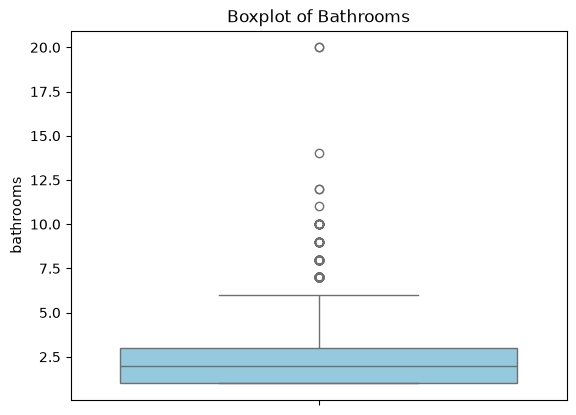

In [5]:
sns.boxplot(y='bathrooms',data=df,color='skyblue')
plt.title("Boxplot of Bathrooms")
plt.show()

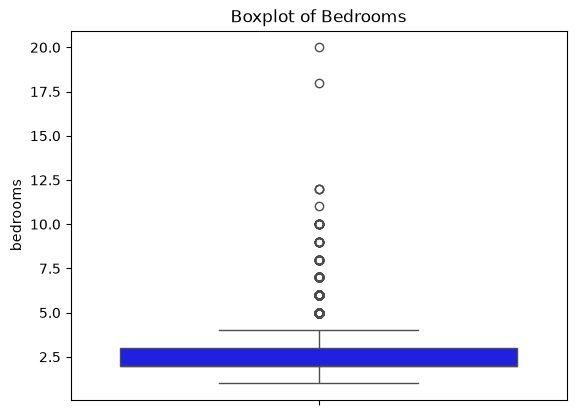

In [6]:
sns.boxplot(y='bedrooms',data=df,color='blue')
plt.title("Boxplot of Bedrooms")
plt.show()

The outliers in both bedrooms and bathrooms are reasonable and can affect price in the sense that category like mansion can have multiple bedrooms and bathrooms so they won't be removed.

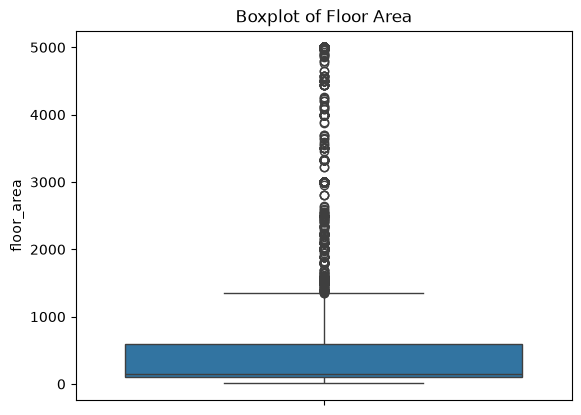

In [7]:
sns.boxplot(y='floor_area',data=df)
plt.title("Boxplot of Floor Area")
plt.show()

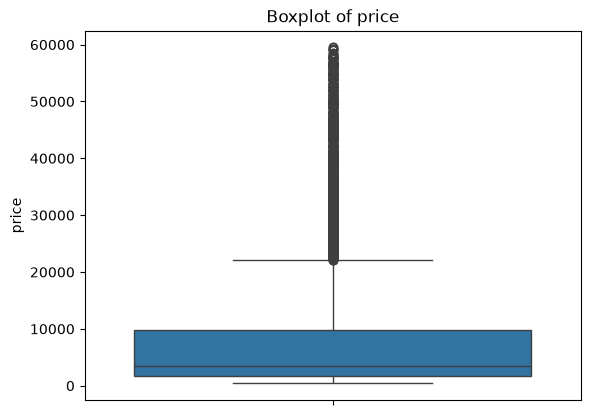

In [8]:
sns.boxplot(y='price',data=df)
plt.title("Boxplot of price")
plt.show()

### Remove Outliers

In [9]:
numerical_col = ['price','floor_area']

for col in numerical_col:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 -Q1
    lower = Q1 -1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower ) & (df[col] <= upper )]

### Visualization after removing outliers

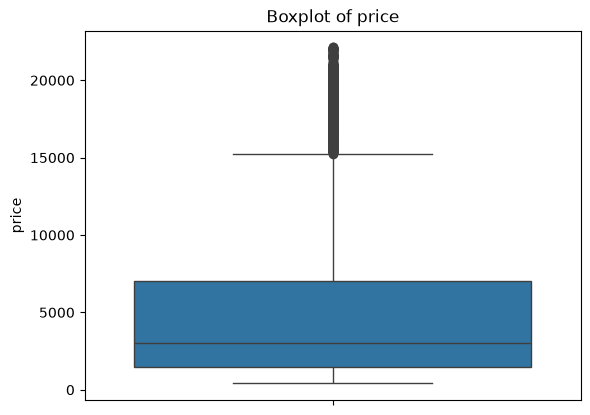

In [10]:
sns.boxplot(y='price',data=df)
plt.title("Boxplot of price")
plt.show()

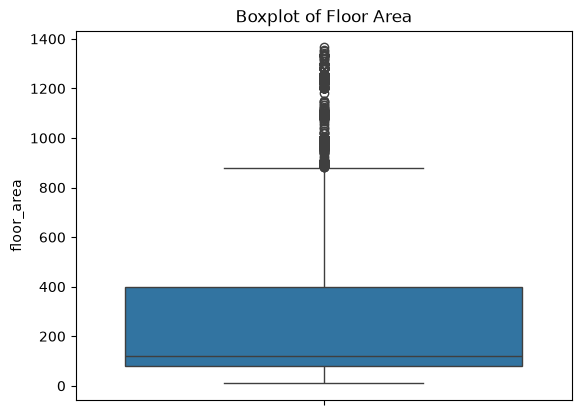

In [11]:
sns.boxplot(y='floor_area',data=df)
plt.title("Boxplot of Floor Area")
plt.show()

### Drop irrelevant columns

In [12]:
df.drop(['lat','lng'], axis=1, inplace = True)

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 14808 entries, 0 to 17886
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          14808 non-null  int64  
 1   category       14808 non-null  str    
 2   bedrooms       14808 non-null  float64
 3   bathrooms      14808 non-null  float64
 4   floor_area     14808 non-null  float64
 5   location       14808 non-null  str    
 6   condition      14808 non-null  str    
 7   amenities      14808 non-null  str    
 8   region         14808 non-null  str    
 9   locality       14808 non-null  str    
 10  parking_space  14808 non-null  bool   
 11  is_furnished   14808 non-null  str    
dtypes: bool(1), float64(3), int64(1), str(7)
memory usage: 4.1 MB


In [14]:
df[['bedrooms','bathrooms', 'floor_area']]=df[['bedrooms','bathrooms', 'floor_area']].astype(int)

In [15]:
df.info()

<class 'pandas.DataFrame'>
Index: 14808 entries, 0 to 17886
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   price          14808 non-null  int64
 1   category       14808 non-null  str  
 2   bedrooms       14808 non-null  int64
 3   bathrooms      14808 non-null  int64
 4   floor_area     14808 non-null  int64
 5   location       14808 non-null  str  
 6   condition      14808 non-null  str  
 7   amenities      14808 non-null  str  
 8   region         14808 non-null  str  
 9   locality       14808 non-null  str  
 10  parking_space  14808 non-null  bool 
 11  is_furnished   14808 non-null  str  
dtypes: bool(1), int64(4), str(7)
memory usage: 4.1 MB


## Check for correlation

In [16]:
from sklearn.preprocessing import OrdinalEncoder

df_temp = df.copy()

# Target-encoded columns (for correlation analysis)
target_cols = ['region', 'locality', 'amenities', 'category', 'location']

for col in target_cols:
    mean_target = df_temp.groupby(col)['price'].mean()
    df_temp[col] = df_temp[col].map(mean_target)

# Ordinal encode condition and is_furnished automatically
# Define order directly in the encoder
ordinal_encoder = OrdinalEncoder(
    categories=[
        ['Used', 'Renovated', 'New'],  # condition order
        ['Unfurnished', 'Semi-furnished', 'Furnished']                                        # is_furnished order
    ],
)
ordinal_cols = ['condition', 'is_furnished']

encoder = OrdinalEncoder()

df_temp[ordinal_cols] = encoder.fit_transform(df_temp[ordinal_cols])



In [17]:
corr = df_temp.corr()['price'].sort_values(ascending=False)
print(corr)

price            1.000000
amenities        0.864539
location         0.584801
locality         0.544583
bathrooms        0.532890
bedrooms         0.488745
category         0.405264
region           0.170552
floor_area       0.053806
parking_space   -0.013331
condition       -0.023828
is_furnished    -0.339689
Name: price, dtype: float64


## Visualize the correlation

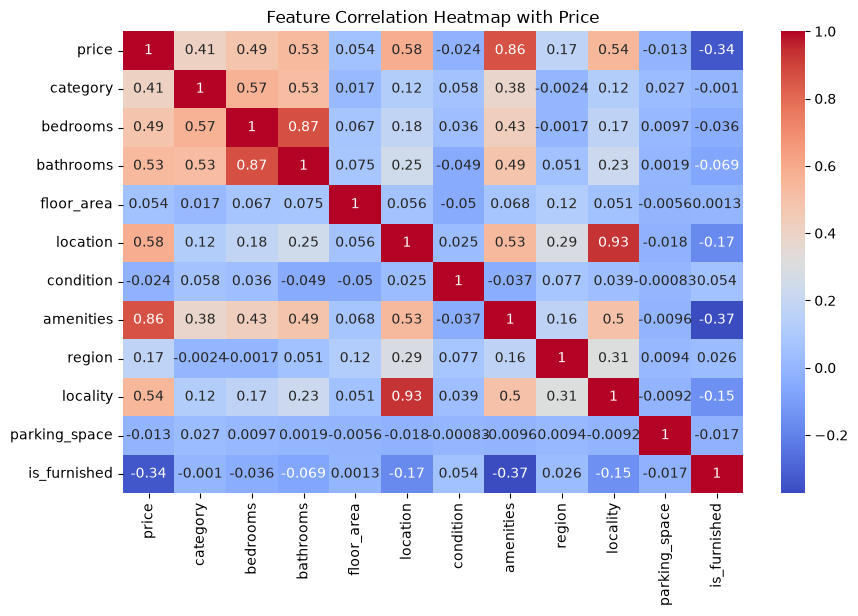

In [18]:
plt.figure(figsize=(10, 6))
sns.heatmap(df_temp.corr(), annot=True, cmap='coolwarm')
plt.title('Feature Correlation Heatmap with Price')
plt.show()

Bedrooms and bathrooms have a strong positive correlation with each other so multicollinearity will be checked for. Same implies for locality and location. 

## Check for multicollinearity 

In [19]:
def _oof_target_mean_encode(
    x_cat: pd.Series,
    y: pd.Series,
    n_splits: int = 5,
    random_state: int = 42,
    smoothing: float = 20.0,
) -> pd.Series:
    """
    Out-of-fold target mean encoding for a single categorical feature.
    Uses smoothing so rare categories shrink toward the global mean.

    smoothing larger means more shrinkage toward global mean.
    """
    x_cat = x_cat.fillna("MISSING").astype(str)
    y = pd.to_numeric(y, errors="coerce")

    oof = pd.Series(index=x_cat.index, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    for train_idx, val_idx in kf.split(x_cat):
        x_tr, x_val = x_cat.iloc[train_idx], x_cat.iloc[val_idx]
        y_tr = y.iloc[train_idx]

        global_mean = y_tr.mean()

        stats = (
            pd.DataFrame({"cat": x_tr, "y": y_tr})
            .groupby("cat")["y"]
            .agg(["mean", "count"])
        )

        # Smoothed mean: (count * cat_mean + smoothing * global_mean) / (count + smoothing)
        stats["smoothed"] = (
            (stats["count"] * stats["mean"] + smoothing * global_mean)
            / (stats["count"] + smoothing)
        )

        mapping = stats["smoothed"].to_dict()
        oof.iloc[val_idx] = x_val.map(mapping).fillna(global_mean).astype(float).values

    return oof


def vif_with_target_mean_encoding(
    df: pd.DataFrame,
    target_col: str,
    numeric_cols=("bedrooms", "bathrooms"),
    cat_cols=("locality", "location"),
    n_splits: int = 5,
    smoothing: float = 20.0,
    random_state: int = 42,
) -> pd.DataFrame:
    """
    Computes VIF after applying out-of-fold target mean encoding to categorical columns.
    Returns a DataFrame sorted by VIF descending.
    """

    cols = list(numeric_cols) + list(cat_cols) + [target_col]
    data = df[cols].copy()

    # Prepare y
    y = pd.to_numeric(data[target_col], errors="coerce")

    # Prepare numeric X
    X = pd.DataFrame(index=data.index)

    for c in numeric_cols:
        X[c] = pd.to_numeric(data[c], errors="coerce")
        X[c] = X[c].fillna(X[c].median())

    # Target mean encode categoricals (out-of-fold)
    for c in cat_cols:
        X[f"{c}_tmean"] = _oof_target_mean_encode(
            x_cat=data[c],
            y=y,
            n_splits=n_splits,
            random_state=random_state,
            smoothing=smoothing,
        )

    # Add constant and compute VIF
    X_for_vif = sm.add_constant(X, has_constant="add")

    vif_rows = []
    for i, col in enumerate(X_for_vif.columns):
        if col == "const":
            continue
        vif_rows.append(
            {
                "feature": col,
                "VIF": float(variance_inflation_factor(X_for_vif.values, i)),
            }
        )

    vif_df = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False).reset_index(drop=True)
    return vif_df





In [20]:
vif_table = vif_with_target_mean_encoding(
    df=df,
    target_col="price",
    numeric_cols=["bedrooms", "bathrooms"],
    cat_cols=["locality", "location"],
    n_splits=5,
    smoothing=20.0,
    random_state=42
)

print(vif_table)


          feature       VIF
0  location_tmean  7.740367
1  locality_tmean  7.684237
2       bathrooms  4.225489
3        bedrooms  4.103533


The Variance Inflation Factor reported that the correlation between location and locality is high. Though not severe, one has to be dropped because a critical look at the dataset reveals some sought of information overlap. Where as the relationship between bathrooms and bedrooms is moderated and could be maintained.

### Drop location

In [21]:
df.drop('location', axis=1, inplace =True)

### Convert amenities strings to lists

In [22]:
import pandas as pd

def split_amenities(x):
    if pd.isna(x):
        return []
    # split by comma, trim spaces, drop empty items
    return [item.strip() for item in str(x).split(",") if item.strip()]

df["amenities"] = df["amenities"].apply(split_amenities)


In [23]:
df['amenities']

0        [24-hour Electricity, Air Conditioning, Balcon...
1        [24-hour Electricity, Air Conditioning, Apartm...
2        [Tiled Floor, Chandelier, Dining Area, Balcony...
3        [Pop Ceiling, Pre-Paid Meter, 24-hour Electric...
4        [Pre-Paid Meter, Dining Area, Chandelier, Balc...
                               ...                        
17881    [Apartment, Balcony, Kitchen Cabinets, Kitchen...
17882    [24-hour Electricity, Air Conditioning, Balcon...
17883    [24-hour Electricity, Air Conditioning, Apartm...
17884    [24-hour Electricity, Apartment, Balcony, Dini...
17886    [24-hour Electricity, Air Conditioning, Apartm...
Name: amenities, Length: 14808, dtype: object

### Drop Parking Space

In [24]:
df.drop('parking_space', axis=1, inplace = True)

#### Save the dataset as processed data to build a pipeline for training our models.

In [25]:
df.to_csv(r"C:\Users\name\Desktop\BIG FOLDER\PROJECTS\My_Projects\ghana_house_rent_project\data\processed_house_rentals.csv",index=False)